In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
DATA_DIR = Path.cwd().parent / 'data' 

In [2]:
df1 = pd.read_pickle(DATA_DIR / 'materials_dataset_v1.pkl')
df2 = pd.read_pickle(DATA_DIR / 'materials_dataset_v2.pkl')

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
def plot_target(df, bins):
    # Set the visual style
    sns.set_theme(style="whitegrid")
    
    # Create a figure with 2 rows and 2 columns
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # --- Row 1: Band Gap ---
    sns.histplot(df['band_gap'], kde=True, ax=axes[0, 0], color='skyblue', bins=bins)
    axes[0, 0].set_title('Band Gap Distribution')
    axes[0, 0].set_xlabel('Band Gap (eV)')
    
    sns.boxplot(x=df['band_gap'], ax=axes[0, 1], color='skyblue')
    axes[0, 1].set_title('Band Gap Outliers')
    
    # --- Row 2: Formation Energy ---
    sns.histplot(df['formation_energy'], kde=True, ax=axes[1, 0], color='salmon', bins=bins)
    axes[1, 0].set_title('Formation Energy Distribution')
    axes[1, 0].set_xlabel('Formation Energy (eV/atom)')
    
    sns.boxplot(x=df['formation_energy'], ax=axes[1, 1], color='salmon')
    axes[1, 1].set_title('Formation Energy Outliers')
    
    plt.tight_layout()
    plt.show()

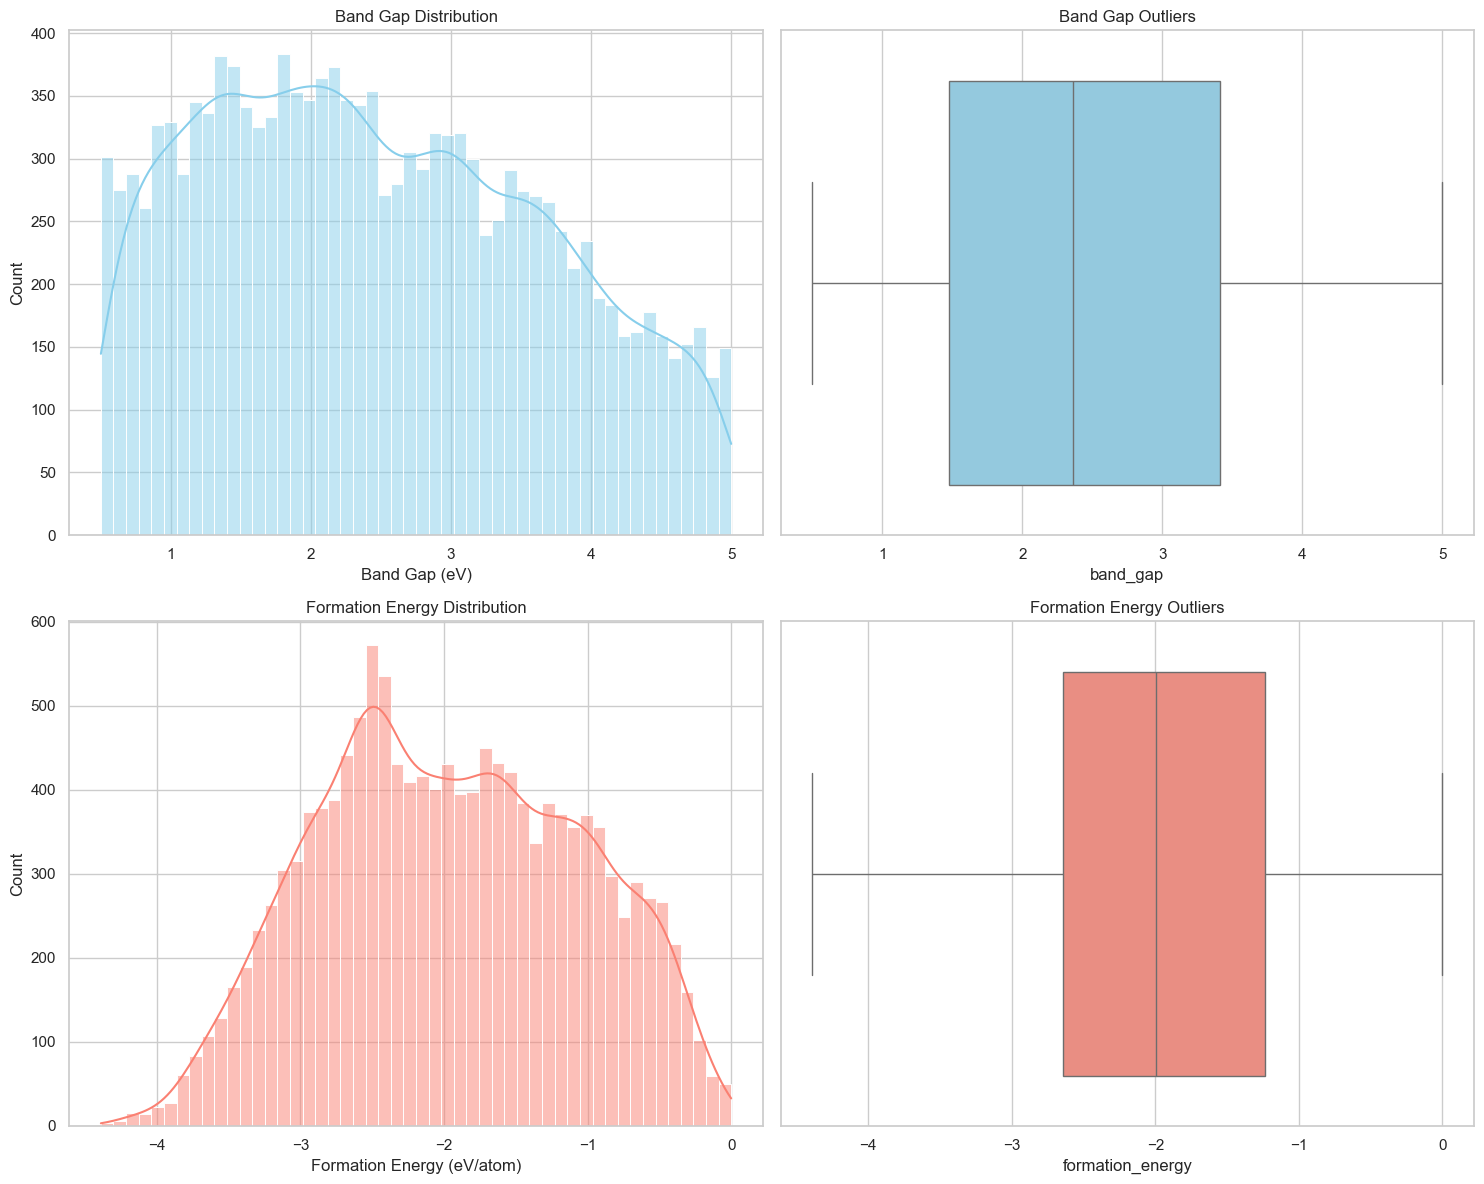

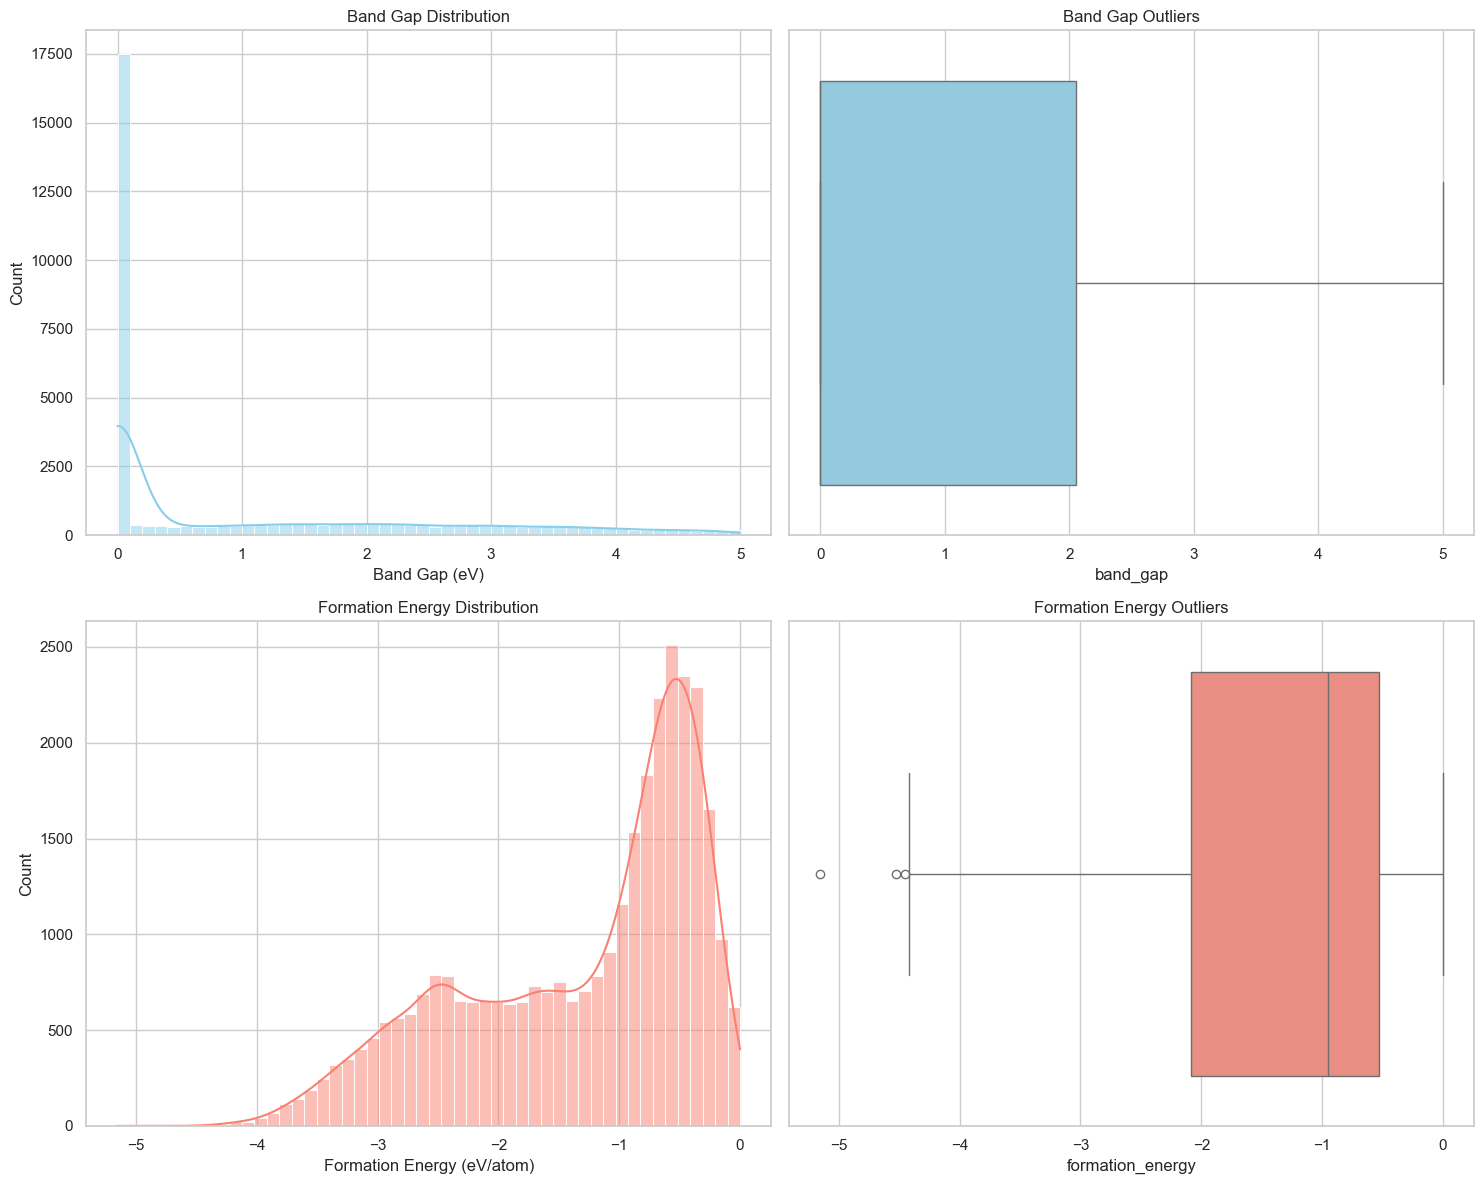

In [5]:
plot_target(df1, 50)
plot_target(df2, 50)

In [6]:
def get_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]
    return outliers, lower_limit, upper_limit

# Check Band Gap
bg_outliers, bg_low, bg_high = get_outliers(df1, 'band_gap')
print(f"BG Outlier Range: Below {bg_low:.2f} or Above {bg_high:.2f}")
print(f"Total FE Outliers: {len(bg_outliers)} out of {len(df1)}")

# Check Formation Energy
fe_outliers, fe_low, fe_high = get_outliers(df1, 'formation_energy')
print(f"FE Outlier Range: Below {fe_low:.2f} or Above {fe_high:.2f}")
print(f"Total FE Outliers: {len(fe_outliers)} out of {len(df1)}")

print()

# Check Band Gap
bg_outliers, bg_low, bg_high = get_outliers(df2, 'band_gap')
print(f"BG Outlier Range: Below {bg_low:.2f} or Above {bg_high:.2f}")
print(f"Total FE Outliers: {len(bg_outliers)} out of {len(df2)}")

# Check Formation Energy
fe_outliers, fe_low, fe_high = get_outliers(df2, 'formation_energy')
print(f"FE Outlier Range: Below {fe_low:.2f} or Above {fe_high:.2f}")
print(f"Total FE Outliers: {len(fe_outliers)} out of {len(df2)}")

BG Outlier Range: Below -1.42 or Above 6.31
Total FE Outliers: 0 out of 13819
FE Outlier Range: Below -4.76 or Above 0.88
Total FE Outliers: 0 out of 13819

BG Outlier Range: Below -3.08 or Above 5.13
Total FE Outliers: 0 out of 32613
FE Outlier Range: Below -4.43 or Above 1.82
Total FE Outliers: 3 out of 32613


In [7]:
df2[df2["band_gap"] == 0.0].head(10)
df2["crystal_system"].isnull().sum()

np.int64(0)

In [8]:
def balance_and_augment_dataset(df, metal_cap=2000, bin_width=0.15, samples_per_bin=600):
    df = df.copy()
    
    # 1. Clean nulls upfront
    df['crystal_system'] = df['crystal_system'].fillna('Unknown')
    
    # 2. Integrity check (fixed null detection)
    unknown_count = df['crystal_system'].isna().sum()
    print(f"Null crystal_system values after fill: {unknown_count}")
    
    # 3. Create is_metal flag
    df['is_metal'] = (df['band_gap'] == 0).astype(int)
    
    # 4. Split
    metals = df[df['is_metal'] == 1].copy()
    semis  = df[df['is_metal'] == 0].copy()
    print(f"Metals: {len(metals)}, Semiconductors: {len(semis)}")
    
    # 5. Stratified subsampling of metals — avoid groupby/apply NaN issue
    metal_parts = []
    for cs, group in metals.groupby('crystal_system', dropna=False):
        if cs == 'Unknown':
            cap = 100
        else:
            cap = metal_cap // 7
        metal_parts.append(group.sample(min(len(group), cap), random_state=42))
    metal_balanced = pd.concat(metal_parts).reset_index(drop=True)
    
    # 6. Bin semiconductors
    semis_low_gap  = semis[semis['band_gap'] < 1.0]
    semis_to_bin   = semis[semis['band_gap'] >= 1.0]
    bins = np.arange(1.0, 5.0 + bin_width, bin_width)
    
    binned_list = [semis_low_gap]
    for i in range(len(bins) - 1):
        lower, upper = bins[i], bins[i + 1]
        bin_data = semis_to_bin[(semis_to_bin['band_gap'] >= lower) & (semis_to_bin['band_gap'] < upper)]
        if len(bin_data) > samples_per_bin:
            bin_data = bin_data.sample(samples_per_bin, random_state=42)
        binned_list.append(bin_data)
    
    # 7. Combine, shuffle, final null check
    balanced_df = pd.concat([metal_balanced] + binned_list).reset_index(drop=True)
    balanced_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)
    
    final_nulls = balanced_df['crystal_system'].isna().sum()
    print(f"Null crystal_system values in output: {final_nulls}")
    print(f"Final dataset size: {len(balanced_df)}")
    
    return balanced_df

Null crystal_system values after fill: 0
Metals: 16884, Semiconductors: 15729
Null crystal_system values in output: 0
Final dataset size: 17579


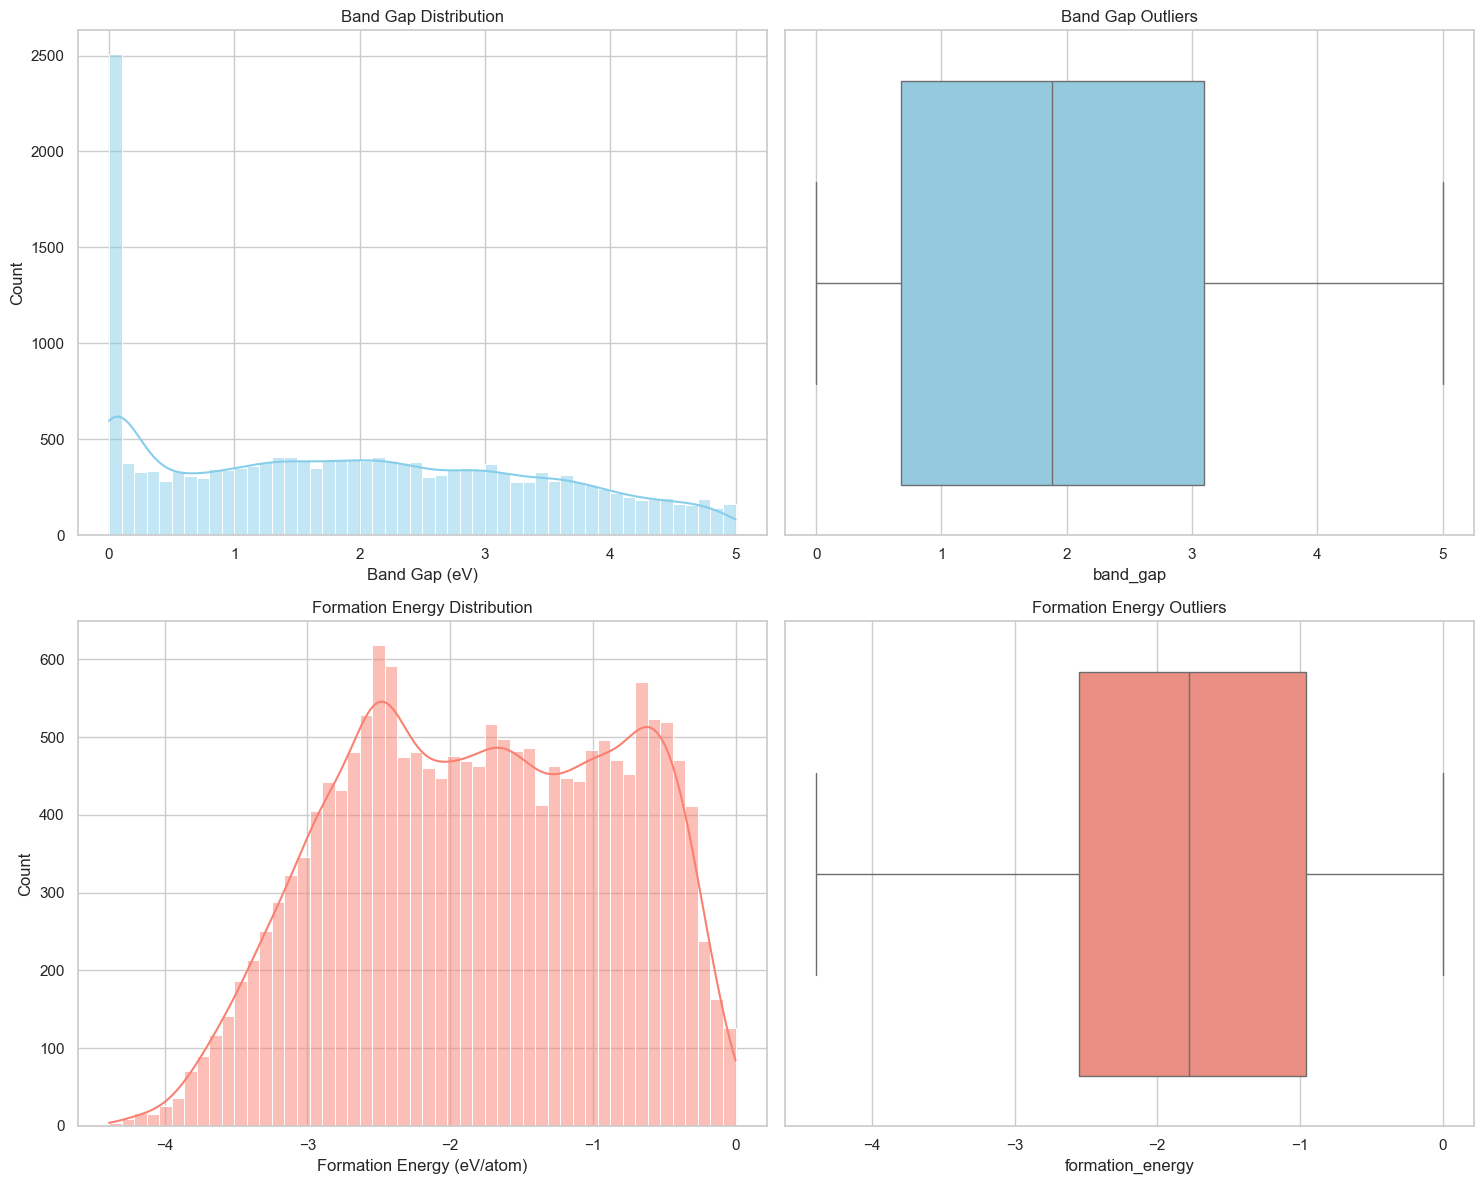

In [9]:
df_balanced = balance_and_augment_dataset(df2)
plot_target(df_balanced, 50)

In [10]:
df_balanced.head(10)

,mp_id,formula,structure,density,nelements,crystal_system,band_gap,formation_energy,is_metal
0,mp-6224,LiScSiO4,"[[0. 0. 0.] Li, [2.432123 0. 5.2649575...",3.094944,4,Orthorhombic,4.6123,-3.373994,0
1,mp-554935,Pr8Sb2S15,"[[10.17553519 2.37204814 4.98861657] Pr, [ 2...",4.909333,3,Tetragonal,1.8140,-1.993167,0
2,mp-12902,ErAgTe2,"[[0.93585873 3.55659165 0. ] Er, [3.688...",7.527977,3,Tetragonal,0.8936,-1.108094,0
3,mp-1209959,NaTm(Pd3O4)2,"[[2.87231596 2.87231596 2.87231596] Na, [0. 0....",8.395122,4,Cubic,0.0221,-1.447312,0
4,mp-569149,K2TeCl6,[[4.14200542e+00 1.46566803e+00 2.06931750e-03...,2.660955,3,Cubic,2.5557,-1.356826,0
5,mp-6639,RbGeSbO5,"[[3.72103408 9.54566655 3.78743374] O, [3.0928...",4.708901,4,Orthorhombic,2.1777,-2.100330,0
6,mp-12494,CsPrCdTe3,[[-2.23377928e-15 4.34730112e+00 9.15068325e...,5.161133,4,Orthorhombic,1.5231,-1.305602,0
7,mp-1203965,KEuH2S2O9,"[[-1.21670325 5.9350468 7.61026919] K, [3.8...",3.099452,5,Monoclinic,0.1963,-2.151761,0
8,mp-10919,Rb2PtC2,[[-2.69961337e-06 3.12109573e+00 1.46090112e...,4.920662,3,Trigonal,1.1362,-0.061142,0
9,mp-675651,MgPS3,"[[2.6871571 1.76028053 8.01276623] Mg, [5.794...",2.303995,3,Monoclinic,2.7986,-1.052410,0


In [11]:
df_balanced[df_balanced["is_metal"] == 1].head(10)

,mp_id,formula,structure,density,nelements,crystal_system,band_gap,formation_energy,is_metal
11,mp-515,TmTl,"[[1.85809132 1.85809132 1.85809132] Tm, [0. 0....",12.079148,2,Cubic,0.0,-0.387423,1
12,mp-530144,Ba6Cu34S27,"[[1.85098388 2.8119005 0.60779684] Ba, [ 4.34...",5.377588,3,Triclinic,0.0,-0.718488,1
29,mp-556868,SrCu2Te2(ClO3)2,"[[7.03314436 3.2841198 4.6613683 ] Sr, [3.345...",4.716700,5,Monoclinic,0.0,-1.649155,1
35,mp-4989,CrNiAs,"[[1.26233486 2.18641883 1.82181335] Cr, [0.578...",7.610264,3,Hexagonal,0.0,-0.212536,1
36,mp-13223,EuMg2Cu9,"[[ 2.535371 -1.46380026 4.02214025] Eu, [ 2...",7.161103,3,Hexagonal,0.0,-0.130788,1
52,mp-567775,La10C4I15,"[[2.30579958 4.65149048 3.62006789] La, [-0.08...",5.201351,3,Triclinic,0.0,-1.481810,1
57,mp-21222,Sm2InGe2,"[[2.13106397 6.14833907 2.39964784] Sm, [2.131...",7.774191,3,Tetragonal,0.0,-0.734377,1
75,mp-21302,Sr2MnGaO5,"[[ 5.4454863 3.16457261 -0.80855767] Sr, [4....",5.053145,4,Orthorhombic,0.0,-2.675952,1
76,mp-5181,LuSnPd2,"[[2.72043205 1.92363576 4.71192703] Lu, [0. 0....",11.370055,3,Cubic,0.0,-0.919037,1
91,mp-22626,OsF6,"[[2.89364197 6.34881761 8.10998747] Os, [0.427...",5.224668,2,Orthorhombic,0.0,-1.780746,1


In [12]:
df_balanced["crystal_system"].isnull().sum()

np.int64(0)

In [ ]:
df_balanced.to_pickle(DATA_DIR / 'materials_dataset_v2_cleaned.pkl')